In [ ]:
import pandas as pd
import zipfile
import urllib.request

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam.zip")

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("spam_dataset")

print("Dataset downloaded successfully!")

In [ ]:
import os

for root, directories, files in os.walk("spam_dataset"):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
import pandas as pd
import os

print("Pandas imported successfully!")

Pandas imported successfully!


In [ ]:
import os

print("Current directory:", os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

print("\nFiles inside spam_dataset:")

if os.path.exists("spam_dataset"):
    for root, dirs, files in os.walk("spam_dataset"):
        for file in files:
            print(os.path.join(root, file))
else:
    print("spam_dataset folder does not exist.")

Current directory: /content

Files in current directory:
['.config', 'sample_data']

Files inside spam_dataset:
spam_dataset folder does not exist.


In [ ]:
import urllib.request
import zipfile
import os

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, "sms_spam.zip")

print("Download completed!")

# Extract the ZIP file
with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("spam_dataset")

print("Dataset extracted successfully!")

Download completed!
Dataset extracted successfully!


In [ ]:
import os

for root, dirs, files in os.walk("spam_dataset"):
    for file in files:
        print(os.path.join(root, file))

spam_dataset/SMSSpamCollection
spam_dataset/readme


In [ ]:
import pandas as pd
import os

dataset_path = None

for root, dirs, files in os.walk("spam_dataset"):
    for file in files:
        if file == "SMSSpamCollection":
            dataset_path = os.path.join(root, file)
            break
    if dataset_path:
        break

if dataset_path:
    df = pd.read_csv(
        dataset_path,
        sep="\t",
        header=None,
        names=["label", "message"]
    )

    print("Dataset loaded successfully!")
    print(df.head())
else:
    print("Dataset file not found. Please check the extracted files.")

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [2]:
import pandas as pd
import os
import zipfile
import urllib.request

# Step 1: Download the dataset if necessary
if not os.path.exists("spam_dataset/SMSSpamCollection"):
    print("Downloading dataset...")

    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

    urllib.request.urlretrieve(url, "sms_spam.zip")

    with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
        zip_ref.extractall("spam_dataset")

    print("Dataset downloaded and extracted!")

# Step 2: Load the dataset
df = pd.read_csv(
    "spam_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

# Step 3: Display the first five records
print("FIRST FIVE RECORDS:")
display(df.head())

# Step 4: Check dataset dimensions
print("\nDATASET SHAPE:")
print(df.shape)

# Step 5: Check column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Step 6: Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Step 7: Count spam and ham messages
print("\nMESSAGE DISTRIBUTION:")
print(df["label"].value_counts())


Dataset downloaded and extracted!
FIRST FIVE RECORDS:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



DATASET SHAPE:
(5572, 2)

COLUMN NAMES:
['label', 'message']

MISSING VALUES:
label      0
message    0
dtype: int64

MESSAGE DISTRIBUTION:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
# Display the first five messages
print("FIRST FIVE RECORDS:")
display(df.head())

# Check the number of rows and columns
print("\nDATASET SHAPE:")
print(df.shape)

# Check column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Count spam and legitimate messages
print("\nMESSAGE DISTRIBUTION:")
print(df["label"].value_counts())

FIRST FIVE RECORDS:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



DATASET SHAPE:
(5572, 2)

COLUMN NAMES:
['label', 'message']

MISSING VALUES:
label      0
message    0
dtype: int64

MESSAGE DISTRIBUTION:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
# Check for missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"]).copy()

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove any unexpected labels
df = df[df["label"].isin(["ham", "spam"])].copy()

# Reset row numbering
df = df.reset_index(drop=True)

print("\nDataset cleaned successfully!")
print("Final dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())

Missing values before cleaning:
label      0
message    0
dtype: int64

Dataset cleaned successfully!
Final dataset shape: (5169, 2)

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


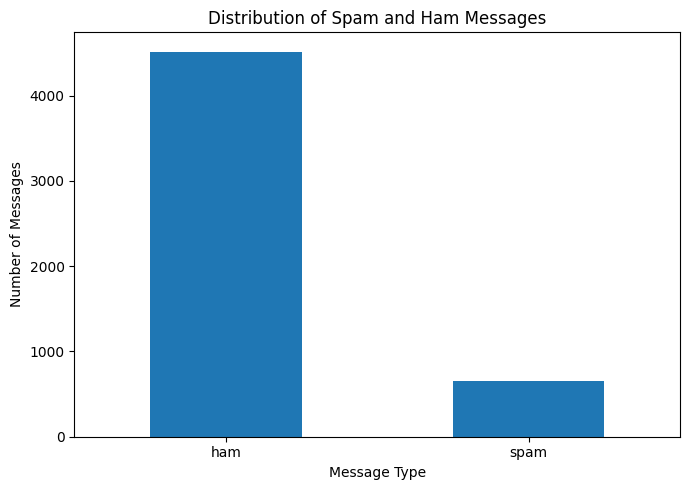

In [6]:
import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Input text
X = df["message"]

# Target labels
y = df["label"]

print("Text features prepared.")
print("Number of messages:", len(X))
print("Number of labels:", len(y))

Text features prepared.
Number of messages: 5169
Number of labels: 5169


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

# Learn vocabulary and transform training messages
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform test messages using the same vocabulary
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training feature matrix: (4135, 7414)
Testing feature matrix: (1034, 7414)


In [10]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
model = MultinomialNB()

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Accuracy:  0.9671 (96.71%)
Precision: 1.0000
Recall:    0.7405
F1-score:  0.8509

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



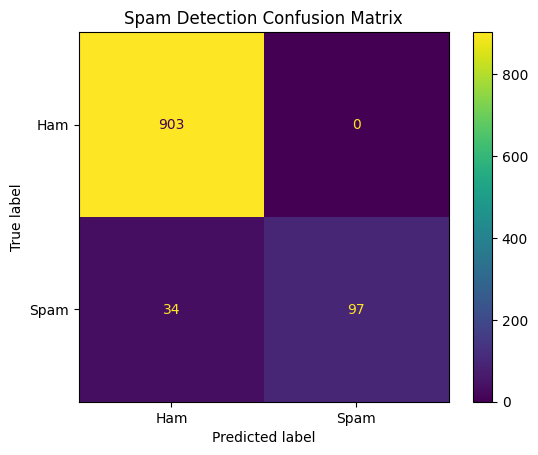

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict labels for test messages
y_pred = model.predict(X_test_tfidf)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="spam",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="spam",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="spam",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot()
plt.title("Spam Detection Confusion Matrix")
plt.show()

In [12]:
def predict_message(message):
    # Convert the new message using the trained vectorizer
    message_tfidf = vectorizer.transform([message])

    # Predict its category
    prediction = model.predict(message_tfidf)[0]

    if prediction == "spam":
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM (NOT SPAM)")

    return prediction


# Test examples
predict_message(
    "Congratulations! You have won a free prize. Claim it now!"
)

predict_message(
    "Hi, are we meeting at the library tomorrow?"
)

Prediction: SPAM
Prediction: HAM (NOT SPAM)


np.str_('ham')

In [13]:
message = input("Enter a message to classify: ")

predict_message(message)

Enter a message to classify: you have won 10000000
Prediction: HAM (NOT SPAM)


np.str_('ham')

In [14]:
import joblib

joblib.dump(model, "spam_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Saved files:")
print("- spam_model.pkl")
print("- tfidf_vectorizer.pkl")

Model saved successfully!
Saved files:
- spam_model.pkl
- tfidf_vectorizer.pkl


In [15]:
from google.colab import files

files.download("spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from sklearn.metrics import accuracy_score, classification_report

# Predict using the test dataset
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("SPAM EMAIL DETECTION - MODEL RESULTS")
print("------------------------------------")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

SPAM EMAIL DETECTION - MODEL RESULTS
------------------------------------
Model Accuracy: 96.71%

Detailed Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



CONFUSION MATRIX
             Predicted Ham  Predicted Spam
Actual Ham             903               0
Actual Spam             34              97


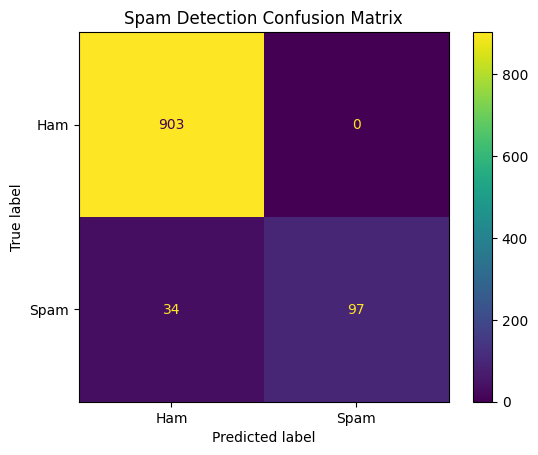

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

print("CONFUSION MATRIX")
print(pd.DataFrame(
    cm,
    index=["Actual Ham", "Actual Spam"],
    columns=["Predicted Ham", "Predicted Spam"]
))

# Visualize the results
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot()
plt.title("Spam Detection Confusion Matrix")
plt.show()